# Importar Librerias

In [ ]:
import pandas as pd
import numpy as np
import sqlite3 as sq


In [ ]:
df = pd.read_excel("/content/FAMILIAS_FOCALIZADAS_PRIMERA_FASE_DEL_PROGRAMA_DE_FAMILIAS_EN_ACCIÓN_ETAPA_IV_DEL_MUNICIPIO_DE_PUERTO_BOYACÁ_20260922 (1).xlsx", dtype=str)

In [ ]:
# Celda de preparación opcional del entorno
# (Se ha removido la lectura de archivos PDF para limpieza del flujo)

In [ ]:
print("=== Columnas del Dataset Original ===")
print(df.info())
print("\n=== Primeras Filas ===")
display(df.head(3))

=== Columnas del Dataset Original ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5543 entries, 0 to 5542
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   Bancarizado                        5485 non-null   object
 1   CodigoDepartamentoAtencion         5543 non-null   object
 2   CodigoMunicipioAtencion            5543 non-null   object
 3   Discapacidad                       5543 non-null   object
 4   EstadoBeneficiario                 5543 non-null   object
 5   Etnia                              5543 non-null   object
 6   FechaInscripcionBeneficiario       5543 non-null   object
 7   Genero                             5543 non-null   object
 8   NivelEscolaridad                   5543 non-null   object
 9   NombreDepartamentoAtencion         5543 non-null   object
 10  NombreMunicipioAtencion            5543 non-null   object
 11  Pais                           

,Bancarizado,CodigoDepartamentoAtencion,CodigoMunicipioAtencion,Discapacidad,EstadoBeneficiario,Etnia,FechaInscripcionBeneficiario,Genero,NivelEscolaridad,NombreDepartamentoAtencion,...,TipoAsignacionBeneficio,TipoBeneficio,TipoDocumento,TipoPoblacion,RangoBeneficioConsolidadoAsignado,RangoUltimoBeneficioAsignado,FechaUltimoBeneficioAsignado,RangoEdad,Titular,CantidadDeBeneficiarios
0,NO,15,15572,SI,ACTIVO,ND,2012-12-01,Mujer,ND,BOYACA,...,ND,ND,TI,DESPLAZADOS,0 - 1.500.000,0 - 1.300.000,1900-01-01,06-17,NO,1
1,NO,15,15572,NO,ACTIVO,ND,2013-08-01,Mujer,PRIMARIA,BOYACA,...,ND,EDUCACIÓN PRIMARIA,TI,DESPLAZADOS,0 - 1.500.000,0 - 1.300.000,1900-01-01,06-17,NO,3
2,ND,15,15572,NO,ACTIVO,ND,2015-09-01,Mujer,ND,BOYACA,...,MONETARIO,NUTRICIÓN,No Definido,DESPLAZADOS,3.000.001 - 4.500.000,0 - 1.300.000,2018-01-01,30-49,SI,1


In [ ]:
# Celda temporal removida para mantener solo el proceso solicitado

# Fase 2: Limpieza de Datos y Diagnóstico Inicial

In [ ]:
# 1. Verificación de registros duplicados
duplicados_iniciales = df.duplicated().sum()
print(f"Registros duplicados iniciales: {duplicados_iniciales}")

# 2. Verificación de valores nulos o vacíos
valores_nulos = df.isnull().sum()
print("\nValores nulos por columna:")
print(valores_nulos[valores_nulos > 0])

# 3. Exploración de valores únicos en columnas clave para identificar anomalías (como 'Nero', 'Ron o gitano', etc.)
columnas_criticas = ['Bancarizado', 'Discapacidad', 'EstadoBeneficiario', 'Etnia', 'Genero', 'NivelEscolaridad', 'TipoPoblacion']
for col in columnas_criticas:
    print(f"\nValores únicos en '{col}':")
    print(df[col].value_counts(dropna=False))

Registros duplicados iniciales: 3592

Valores nulos por columna:
Bancarizado    58
dtype: int64

Valores únicos en 'Bancarizado':
Bancarizado
SI     4070
NO     1288
ND      127
NaN      58
Name: count, dtype: int64

Valores únicos en 'Discapacidad':
Discapacidad
NO    5412
ND      77
SI      54
Name: count, dtype: int64

Valores únicos en 'EstadoBeneficiario':
EstadoBeneficiario
ACTIVO       4826
NO ACTIVO     717
Name: count, dtype: int64

Valores únicos en 'Etnia':
Etnia
ND                        5069
AFROCOLOMBIANO – NEGRO     401
ROM O GITANO                51
INDIGENA                    17
RAIZAL                       2
MESTIZO                      2
PALENQUERO                   1
Name: count, dtype: int64

Valores únicos en 'Genero':
Genero
Mujer     4603
Hombre     938
ND           2
Name: count, dtype: int64

Valores únicos en 'NivelEscolaridad':
NivelEscolaridad
ND                 5034
PRIMARIA            197
SECUNDARIA          195
TRANSICION           87
SIN ESPECIFICAR    

In [ ]:
# 1. Hacer una copia para trabajar de forma segura
df_clean = df.copy()

# 2. Eliminar registros duplicados
df_clean = df_clean.drop_duplicates()
print(f"Registros después de eliminar duplicados: {df_clean.shape[0]}")

# 3. Tratar valores nulos en la columna 'Bancarizado'
df_clean['Bancarizado'] = df_clean['Bancarizado'].fillna('ND')

# 4. Asegurar tipos de datos correctos
# Convertir cantidad de beneficiarios a entero
df_clean['CantidadDeBeneficiarios'] = pd.to_numeric(df_clean['CantidadDeBeneficiarios'], errors='coerce').fillna(1).astype(int)

# Convertir fechas a formato datetime de forma segura
df_clean['FechaInscripcionBeneficiario'] = pd.to_datetime(df_clean['FechaInscripcionBeneficiario'], errors='coerce')
df_clean['FechaUltimoBeneficioAsignado'] = pd.to_datetime(df_clean['FechaUltimoBeneficioAsignado'], errors='coerce')

print("\nVerificación de nulos en el nuevo dataframe:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
print("\nLimpieza básica completada con éxito.")

Registros después de eliminar duplicados: 1951

Verificación de nulos en el nuevo dataframe:
Series([], dtype: int64)

Limpieza básica completada con éxito.


# Fase 3: Análisis Exploratorio de Datos (EDA) y Fase 4: Consultas SQL

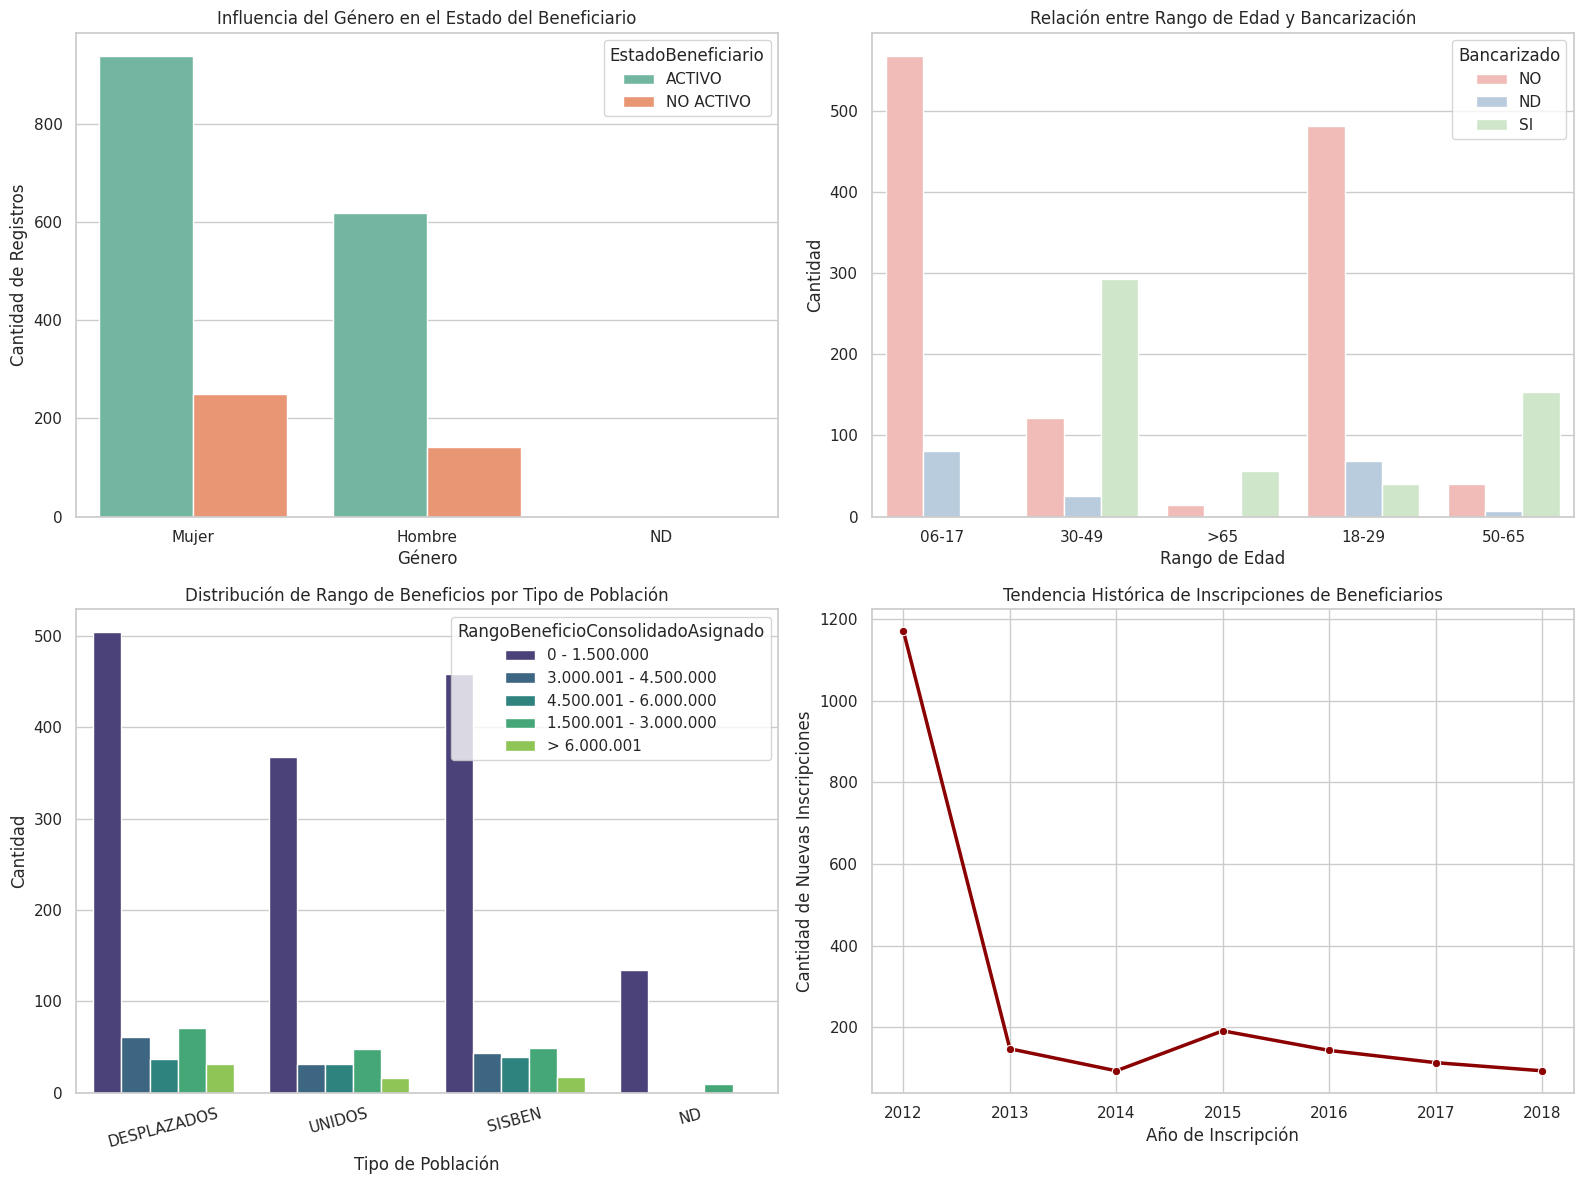

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Género vs Estado del Beneficiario
sns.countplot(data=df_clean, x='Genero', hue='EstadoBeneficiario', ax=axes[0,0], palette='Set2')
axes[0,0].set_title('Influencia del Género en el Estado del Beneficiario')
axes[0,0].set_xlabel('Género')
axes[0,0].set_ylabel('Cantidad de Registros')

# 2. Rango de Edad vs Bancarizado
sns.countplot(data=df_clean, x='RangoEdad', hue='Bancarizado', ax=axes[0,1], palette='Pastel1')
axes[0,1].set_title('Relación entre Rango de Edad y Bancarización')
axes[0,1].set_xlabel('Rango de Edad')
axes[0,1].set_ylabel('Cantidad')

# 3. Tipo de Población vs Rango Beneficio Consolidado
sns.countplot(data=df_clean, x='TipoPoblacion', hue='RangoBeneficioConsolidadoAsignado', ax=axes[1,0], palette='viridis')
axes[1,0].set_title('Distribución de Rango de Beneficios por Tipo de Población')
axes[1,0].set_xlabel('Tipo de Población')
axes[1,0].set_ylabel('Cantidad')
axes[1,0].tick_params(axis='x', rotation=15)

# 4. Tendencia histórica de inscripciones (Agrupado por Año de Inscripción)
df_clean['AnioInscripcion'] = df_clean['FechaInscripcionBeneficiario'].dt.year
tendencia = df_clean.groupby('AnioInscripcion').size().reset_index(name='Inscripciones')
sns.lineplot(data=tendencia, x='AnioInscripcion', y='Inscripciones', marker='o', ax=axes[1,1], color='darkred', linewidth=2.5)
axes[1,1].set_title('Tendencia Histórica de Inscripciones de Beneficiarios')
axes[1,1].set_xlabel('Año de Inscripción')
axes[1,1].set_ylabel('Cantidad de Nuevas Inscripciones')

plt.tight_layout()
plt.show()

In [ ]:
# Configuración e Importación a Base de Datos Relacional SQLite integrada en Colab
# Convertimos las columnas de fecha a texto para guardarlas adecuadamente en SQLite
df_db = df_clean.copy()
df_db['FechaInscripcionBeneficiario'] = df_db['FechaInscripcionBeneficiario'].astype(str)
df_db['FechaUltimoBeneficioAsignado'] = df_db['FechaUltimoBeneficioAsignado'].astype(str)

# Conectar a base de datos SQLite en memoria
conn = sq.connect("programa_familias.db")
cursor = conn.cursor()

# Guardar el dataframe en la tabla 'beneficiarios'
df_db.to_sql('beneficiarios', conn, if_exists='replace', index=False)
print("Base de datos SQLite creada exitosamente y tabla 'beneficiarios' cargada.")

# Función auxiliar para mostrar resultados de consultas SQL en formato DataFrame
def ejecutar_consulta(query):
    return pd.read_sql_query(query, conn)

Base de datos SQLite creada exitosamente y tabla 'beneficiarios' cargada.


In [ ]:
print("=== PREGUNTA 1: ¿Cómo influye el género del titular en el estado del beneficiario? ===")
q1 = """
SELECT Genero, EstadoBeneficiario, COUNT(*) as Total_Beneficiarios
FROM beneficiarios
GROUP BY Genero, EstadoBeneficiario;
"""
display(ejecutar_consulta(q1))

print("\n=== PREGUNTA 2: ¿Existe relación entre el rango de edad y la bancarización? ===")
q2 = """
SELECT RangoEdad, Bancarizado, COUNT(*) as Total_Beneficiarios
FROM beneficiarios
GROUP BY RangoEdad, Bancarizado
ORDER BY RangoEdad, Total_Beneficiarios DESC;
"""
display(ejecutar_consulta(q2))

print("\n=== PREGUNTA 3: ¿Cómo se distribuyen los rangos de beneficios asignados según tipo de población? ===")
q3 = """
SELECT TipoPoblacion, RangoBeneficioConsolidadoAsignado, COUNT(*) as Cantidad_Beneficiarios
FROM beneficiarios
GROUP BY TipoPoblacion, RangoBeneficioConsolidadoAsignado
ORDER BY TipoPoblacion, Cantidad_Beneficiarios DESC;
"""
display(ejecutar_consulta(q3))

print("\n=== PREGUNTA 4: ¿Cuál ha sido la tendencia histórica de las inscripciones de beneficiarios? ===")
q4 = """
SELECT strftime('%Y', FechaInscripcionBeneficiario) as Anio, COUNT(*) as Total_Inscritos
FROM beneficiarios
WHERE FechaInscripcionBeneficiario IS NOT NULL AND FechaInscripcionBeneficiario != 'NaT'
GROUP BY Anio
ORDER BY Anio;
"""
display(ejecutar_consulta(q4))

=== PREGUNTA 1: ¿Cómo influye el género del titular en el estado del beneficiario? ===


,Genero,EstadoBeneficiario,Total_Beneficiarios
0,Hombre,ACTIVO,619
1,Hombre,NO ACTIVO,142
2,Mujer,ACTIVO,938
3,Mujer,NO ACTIVO,250
4,ND,ACTIVO,2



=== PREGUNTA 2: ¿Existe relación entre el rango de edad y la bancarización? ===


,RangoEdad,Bancarizado,Total_Beneficiarios
0,06-17,NO,568
1,06-17,ND,81
2,18-29,NO,482
3,18-29,ND,69
4,18-29,SI,40
5,30-49,SI,293
6,30-49,NO,121
7,30-49,ND,25
8,50-65,SI,153
9,50-65,NO,40



=== PREGUNTA 3: ¿Cómo se distribuyen los rangos de beneficios asignados según tipo de población? ===


,TipoPoblacion,RangoBeneficioConsolidadoAsignado,Cantidad_Beneficiarios
0,DESPLAZADOS,0 - 1.500.000,504
1,DESPLAZADOS,1.500.001 - 3.000.000,71
2,DESPLAZADOS,3.000.001 - 4.500.000,61
3,DESPLAZADOS,4.500.001 - 6.000.000,37
4,DESPLAZADOS,> 6.000.001,32
5,ND,0 - 1.500.000,134
6,ND,1.500.001 - 3.000.000,10
7,ND,3.000.001 - 4.500.000,1
8,SISBEN,0 - 1.500.000,458
9,SISBEN,1.500.001 - 3.000.000,49



=== PREGUNTA 4: ¿Cuál ha sido la tendencia histórica de las inscripciones de beneficiarios? ===


,Anio,Total_Inscritos
0,2012,1171
1,2013,147
2,2014,93
3,2015,191
4,2016,143
5,2017,113
6,2018,93


# Guardar Tambien en Excel

In [16]:
# Guardar el DataFrame corregido en un nuevo archivo de Excel
ruta_salida = '/content/datos_limpios_familias.xlsx'
df_clean.to_excel(ruta_salida, index=False)
print(f"¡Datos limpios exportados exitosamente a: {ruta_salida}!")

¡Datos limpios exportados exitosamente a: /content/datos_limpios_familias.xlsx!
